<a href="https://colab.research.google.com/github/LEROYCICE/DifferenceFiniPDE/blob/main/tp3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [78]:
import numpy as np
from numpy.fft import fft, ifft
import matplotlib.pyplot as plt

# EXERCICE 1 : Signaux de fréquences variables dans le temps

##Question 1 : Définition et affichage du signal u

In [79]:
N = 2048
k1 = 45
k2 = 233
n = np.arange(N)

In [80]:
u = np.zeros(N)
u[:N//2] = np.sin(2 * np.pi * k1 * n[:N//2] / N)
u[N//2:] = np.sin(2 * np.pi * k2 * n[N//2:] / N)

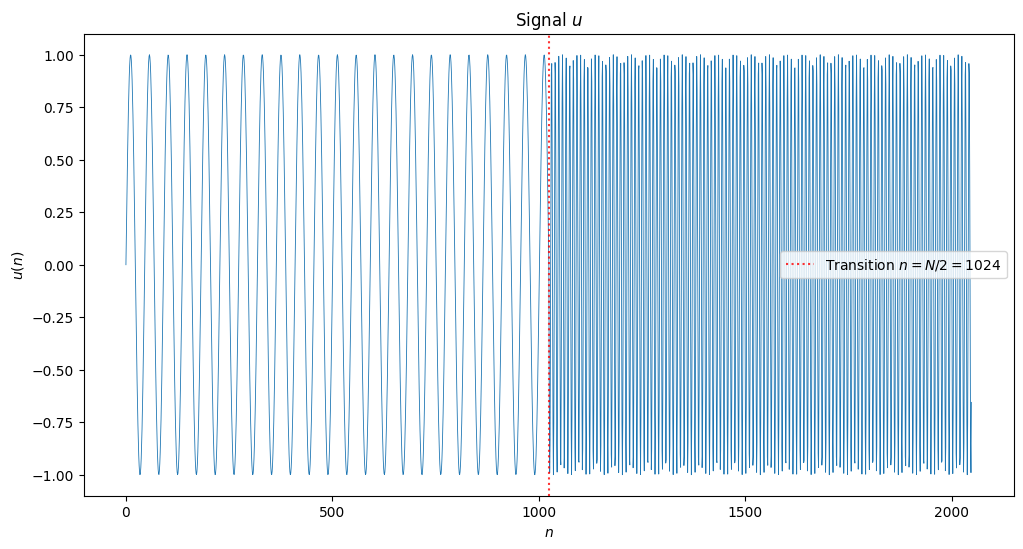

In [51]:
plt.figure(figsize=(12,6))
plt.plot(n,u, linewidth=0.6)
plt.title("Signal $u$")
plt.xlabel("$n$")
plt.ylabel("$u(n)$")
plt.axvline(x=N//2, color='r', linestyle=':', alpha=0.8, label=f"Transition $n = N/2 = {N//2}$")
plt.legend()

## Commentaire:
On observe clairement deux zones distinctes dans le signal :
- Pour $ n < 1024$ , le signal oscille lentement (fréquence $k_1$ = 45)
- Pour $n \geq 1024$, le signal oscille beaucoup plus rapidement (fréquence $k_2$ = 223)

- Le contenu fréquentiel du signal change brusquement à $n = N/2$.

## Question 2 : Spectre d'amplitude de u

In [52]:
u_hat = fft(u)

Text(0, 0.5, '$|\\hat{u}(k)|$')

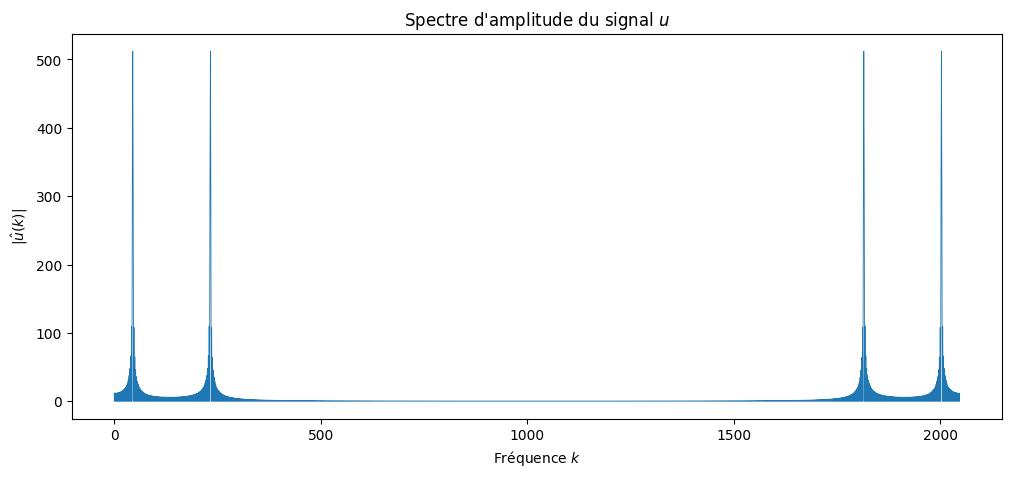

In [53]:
plt.figure(figsize=(12,5))
plt.plot(n, np.abs(u_hat), linewidth=0.6)
plt.title("Spectre d'amplitude du signal $u$")
plt.xlabel("Fréquence $k$")
plt.ylabel("$|\\hat{u}(k)|$")

## Commentaire:
- Le spectre d'amplitude montre 4 pics principaux (aux fréquences $ k_1, k_2, N-k_1, N-k_2 $),
mais ils sont élargis et ne sont pas des Diracs purs. Cela est dû au fait que chaque sinusoïde n'est présente que sur la moitié du signal (multilplication par une fenêtre rectangulaire = convolution par un sinc en fréquence).

- Le spectre global ne permet pas de dire QUAND chaque fréquence apparaît.

## Question 3 : TFD sur les deux moitiés v1 et v2

In [54]:
v1 = u[:N//2]
v2 = u[N//2:]
v1_hat = fft(v1)
v2_hat = fft(v2)

Text(0, 0.5, '$|\\hat{v}_2(k)|$')

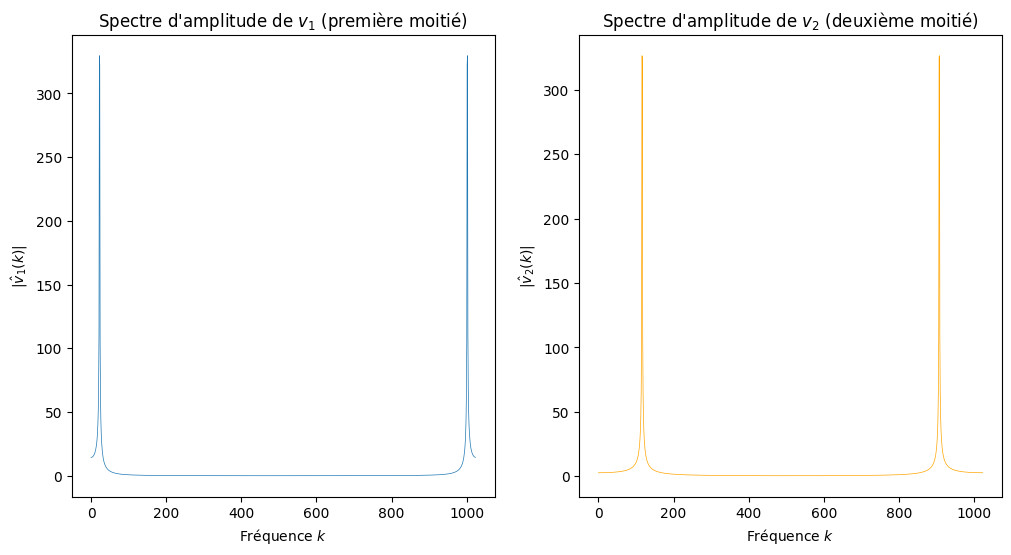

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
# Spectre v1
axes[0].plot(np.arange(N//2), np.abs(v1_hat), linewidth=0.5)
axes[0].set_title("Spectre d'amplitude de $v_1$ (première moitié)")
axes[0].set_xlabel("Fréquence $k$")
axes[0].set_ylabel("$|\\hat{v}_1(k)|$")

# Spectre v2
axes[1].plot(np.arange(N//2), np.abs(v2_hat), linewidth=0.5, color='orange')
axes[1].set_title("Spectre d'amplitude de $v_2$ (deuxième moitié)")
axes[1].set_xlabel("Fréquence $k$")
axes[1].set_ylabel("$|\\hat{v}_2(k)|$")

## Commentaire:
En séparant le signal en deux moitiés et en calculant la TFD sur chacune :
- Le spectre de v1 présente un pic net autour de $k_\frac{1}{2} ≈ 22.5 $ (fréquence ramenée à la taille $N/2$). C'est la fréquence $k_1$ = 45 du signal original.
- Le spectre de v2 présente un pic net autour de $k_\frac{2}{2} ≈ 111.5$ (fréquence $k_2 = 223$).

Contrairement au spectre global de la question 2, on identifie clairement chaque fréquence séparément.

## Question 4 : Explication théorique (produit ↔ convolution)

In [56]:
g = np.zeros(N)
g[:N//2] = 1
v1_tilde = np.sin(2 * np.pi * k1 * n / N)
v2_tilde = np.sin(2 * np.pi * k2 * n / N)

In [57]:
u_recompose = g * v1_tilde + (1 - g) * v2_tilde

g_hat = fft(g)

Text(0.5, 0, 'Fréquence $k$')

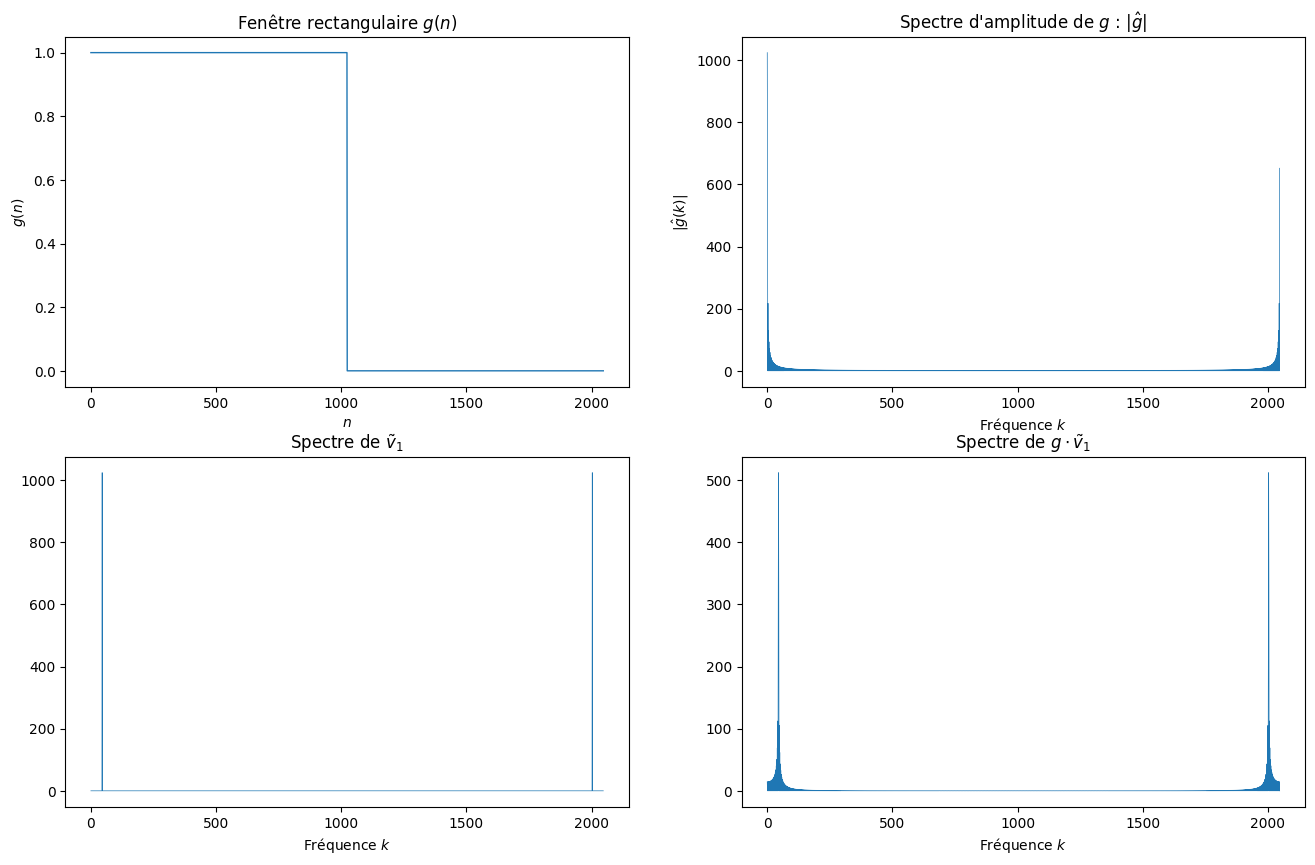

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Affichage de g
axes[0, 0].plot(n, g, linewidth=1.0)
axes[0, 0].set_title("Fenêtre rectangulaire $g(n)$")
axes[0, 0].set_xlabel("$n$")
axes[0, 0].set_ylabel("$g(n)$")

# Affichage du spectre de g (type sinc)
axes[0, 1].plot(np.arange(N), np.abs(g_hat), linewidth=0.5)
axes[0, 1].set_title("Spectre d'amplitude de $g$ : $|\\hat{g}|$")
axes[0, 1].set_xlabel("Fréquence $k$")
axes[0, 1].set_ylabel("$|\\hat{g}(k)|$")

# Spectre de ṽ1 (Diracs purs en k1 et N-k1)
axes[1, 0].plot(np.arange(N), np.abs(fft(v1_tilde)), linewidth=0.5)
axes[1, 0].set_title("Spectre de $\\tilde{v}_1$")
axes[1, 0].set_xlabel("Fréquence $k$")

# Spectre de g · ṽ1 (convolution → élargissement)
axes[1, 1].plot(np.arange(N), np.abs(fft(g * v1_tilde)), linewidth=0.5)
axes[1, 1].set_title("Spectre de $g \\cdot \\tilde{v}_1$")
axes[1, 1].set_xlabel("Fréquence $k$")

## Commentaire:
- Le signal u s'exprime comme $ u = g \ast \tilde{v_1} + (1-g)\ast \tilde{v_2} $.
- La TFD d'un produit est proportionnelle à la convolution circulaire des TFD :
- $F(g \ast \tilde{v_1}) = (1/N) \hat{g} \ast \hat{c}v_1$
- Le spectre de $\tilde{v_1}$ est un couple de Diracs (aux fréquences k1 et N-k1).
- Le spectre de g est un sinus cardinal discret (sinc) avec des lobes latéraux.
- La convolution des Diracs par le sinc produit des pics élargis : c'est la fuite
- spectrale (spectral leakage). Ce phénomène explique pourquoi les pics dans le
- pectre de u (Q1.2) ne sont pas fins mais ont une largeur non négligeable.


## Question 5: Signal chirp

In [59]:
kv = k1 + n * (k2 - k1) / N
w = np.sin(2 * np.pi * n * kv / N)

Text(0, 0.5, '$|\\hat{w}(k)|$')

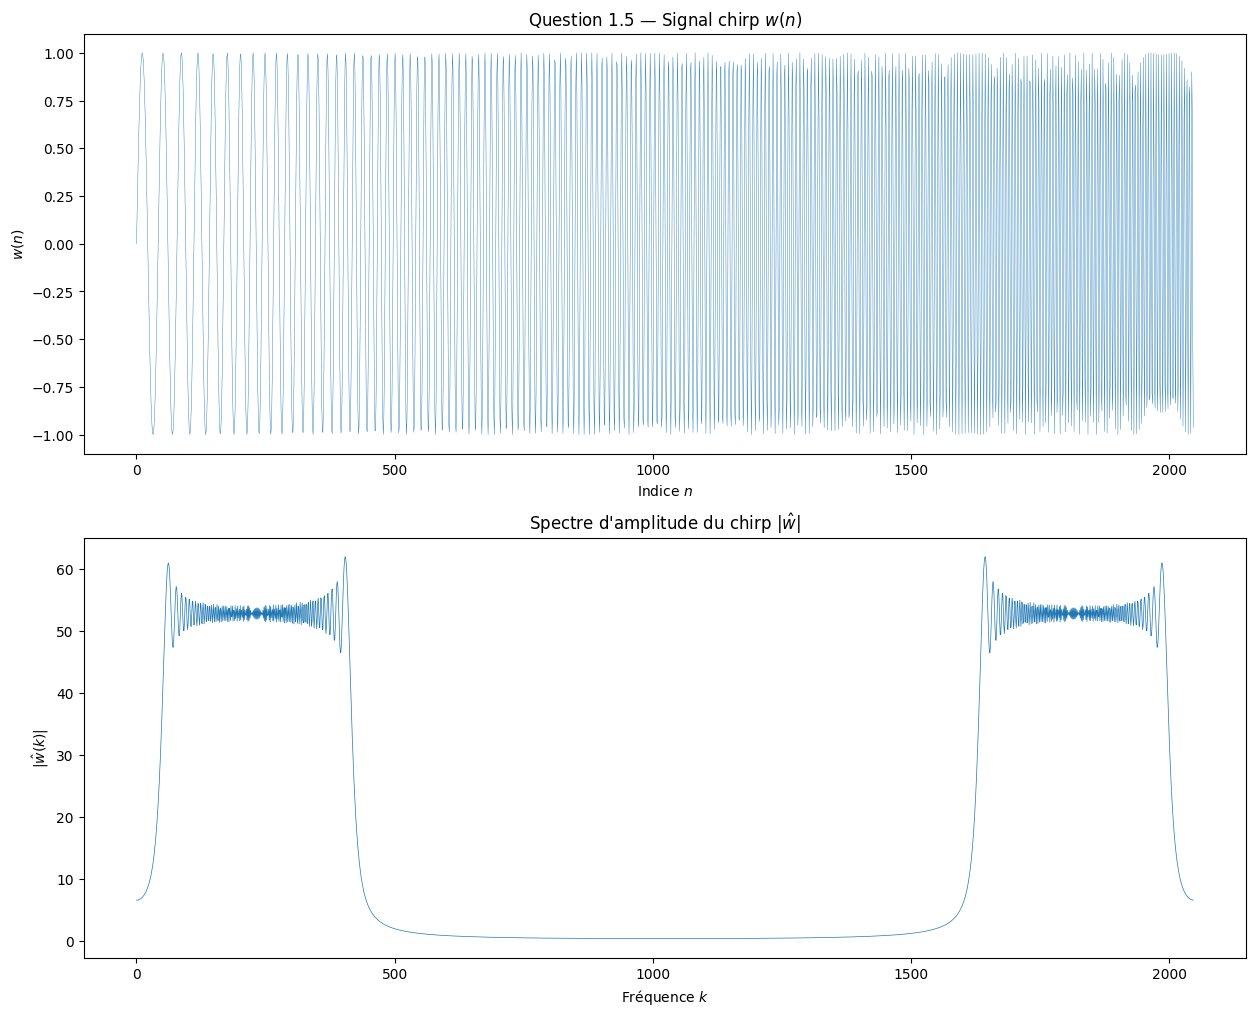

In [60]:
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# Affichage du chirp
axes[0].plot(n, w, linewidth=0.3)
axes[0].set_title("Question 1.5 — Signal chirp $w(n)$")
axes[0].set_xlabel("Indice $n$")
axes[0].set_ylabel("$w(n)$")

# Spectre d'amplitude du chirp
w_hat = fft(w)

axes[1].plot(np.arange(N), np.abs(w_hat), linewidth=0.5)
axes[1].set_title("Spectre d'amplitude du chirp $|\\hat{w}|$")
axes[1].set_xlabel("Fréquence $k$")
axes[1].set_ylabel("$|\\hat{w}(k)|$")

## Commentaire :
- Le signal chirp w varie progressivement de la fréquence $k_1$ à $k_2$.
- Visuellement, on observe une oscillation qui s'accélère au fil du temps.
- Le spectre d'amplitude montre une bande large et relativement plate entre k1 et k2 et symétriquement entre $ N-k_2$ et $N-k_1$.

## Question 6: Estimation de la réponse fréquentielle d'un filtre

In [61]:
h = np.zeros(N)
h[0] = -1.0
h[1] = 1.0

In [62]:
# Convolution circulaire h * w dans le domaine de Fourier
h_hat = fft(h)
y_clean = np.real(ifft(h_hat * w_hat))   # y sans bruit

# Ajout du bruit gaussien
sigma = 0.12
e = np.random.normal(0, sigma, N)
y = y_clean + e

In [63]:
y_hat = fft(y)

# Pour éviter la division par zéro, on utilise une régularisation
epsilon = 1e-6
h_hat_estime = y_hat / (w_hat + epsilon * (np.abs(w_hat) < epsilon))
h_estime = np.real(ifft(h_hat_estime))

erreur_base = np.linalg.norm(h_estime - h)
print(f"\nQuestion 1.6 — Estimation du filtre h avec k1={k1}, k2={k2}")
print(f"  Erreur ‖h★ - h‖₂ = {erreur_base:.6f}")

# --- Test de l'impact de k1 et k2 ---
print(f"\n--- Impact de k1 et k2 sur l'estimation ---")


Question 1.6 — Estimation du filtre h avec k1=45, k2=233
  Erreur ‖h★ - h‖₂ = 8.087341

--- Impact de k1 et k2 sur l'estimation ---


In [64]:
# On teste différentes paires (k1, k2)
paires_k = [
    (1, 1023),     # Bande maximale (presque tout le spectre)
    (1, 512),      # Grande bande
    (45, 223),     # Valeurs du TP
    (100, 200),    # Bande moyenne
    (200, 250),    # Bande étroite
    (45, 50),      # Très petite bande
]

erreurs = []
for k1_test, k2_test in paires_k:
    # Recalculer le chirp avec les nouvelles fréquences
    kv_test = k1_test + n * (k2_test - k1_test) / N
    w_test = np.sin(2 * np.pi * n * kv_test / N)
    w_test_hat = fft(w_test)

    # Convolution et ajout de bruit
    y_test_clean = np.real(ifft(h_hat * w_test_hat))
    y_test = y_test_clean + e  # Même bruit pour comparaison équitable

    # Estimation
    y_test_hat = fft(y_test)
    h_hat_test = y_test_hat / (w_test_hat + epsilon * (np.abs(w_test_hat) < epsilon))
    h_test_estime = np.real(ifft(h_hat_test))

    err = np.linalg.norm(h_test_estime - h)
    erreurs.append(err)
    print(f"  k1={k1_test:4d}, k2={k2_test:4d} → ‖h★ - h‖₂ = {err:.6f}")

  k1=   1, k2=1023 → ‖h★ - h‖₂ = 4.124685
  k1=   1, k2= 512 → ‖h★ - h‖₂ = 0.171028
  k1=  45, k2= 223 → ‖h★ - h‖₂ = 8.795318
  k1= 100, k2= 200 → ‖h★ - h‖₂ = 17.176224
  k1= 200, k2= 250 → ‖h★ - h‖₂ = 32.017605
  k1=  45, k2=  50 → ‖h★ - h‖₂ = 412.126263


Text(0, 0.5, '$\\|h^\\star - h\\|_2$')

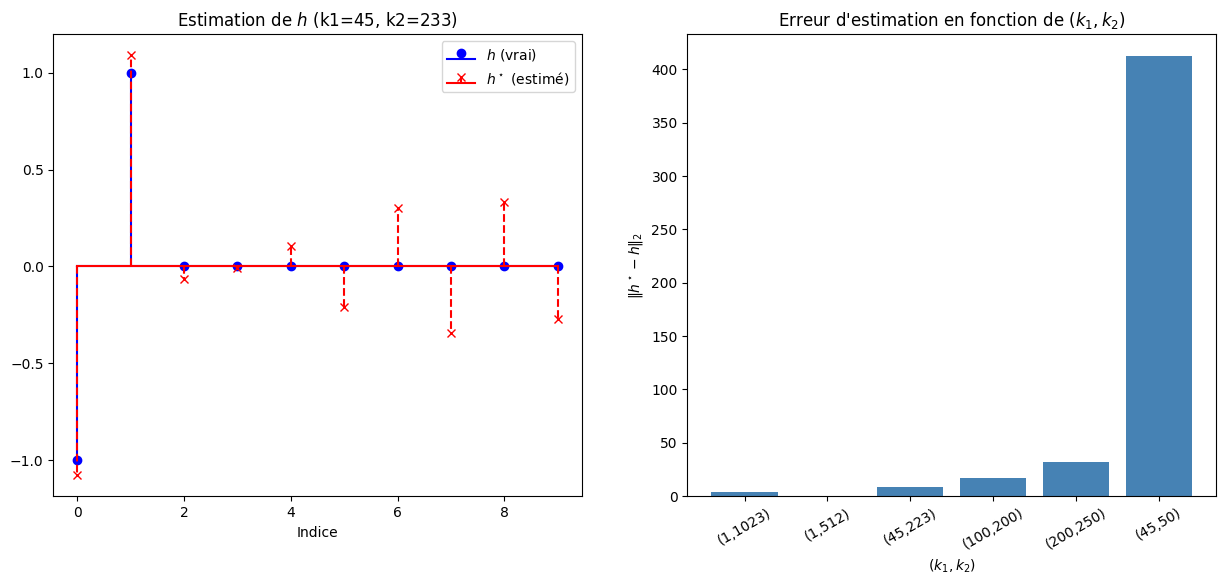

In [65]:
# Affichage des résultats
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Estimation avec k1=45, k2=223 (valeurs du TP)
axes[0].stem(np.arange(10), h[:10], markerfmt='bo', linefmt='b-', basefmt='b-', label='$h$ (vrai)')
axes[0].stem(np.arange(10), h_estime[:10], markerfmt='rx', linefmt='r--', basefmt='r-', label='$h^\\star$ (estimé)')
axes[0].set_title(f"Estimation de $h$ (k1={k1}, k2={k2})")
axes[0].set_xlabel("Indice")
axes[0].legend()

# Erreur en fonction de la bande passante du chirp
bandes = [k2_t - k1_t for k1_t, k2_t in paires_k]
axes[1].bar(range(len(paires_k)), erreurs, color='steelblue')
axes[1].set_xticks(range(len(paires_k)))
axes[1].set_xticklabels([f"({k1_t},{k2_t})" for k1_t, k2_t in paires_k], rotation=30)
axes[1].set_title("Erreur d'estimation en fonction de $(k_1, k_2)$")
axes[1].set_xlabel("$(k_1, k_2)$")
axes[1].set_ylabel("$\\|h^\\star - h\\|_2$")


## Commentaire :
#### On estime h par déconvolution dans le domaine de Fourier : $\hat{h^\star} = \hat{y} / \hat{w}$.
#### La qualité de l'estimation dépend directement de la bande passante du chirp :
- Si $(k_1, k_2)$ couvre une large bande (ex: 1 à 1023), le chirp excite presque
toutes les fréquences par consequent l'estimation est bonne (erreur faible).
- Si la bande est étroite (ex: 45 à 50), les fréquences non excitées par le chirp
produisent de grandes erreurs (division par des valeurs proches de zéro, amplification
du bruit) par consequent l'estimation est mauvaise.
#### Le meilleur choix est donc $k_1≈1$, $k_2≈N/2$ pour couvrir tout le spectre.

# EXERCICE 2 : Spectrogramme et Transformée de Fourier à Court Terme

## Question 1: Implémentation du spectrogramme basique

In [66]:
def spectrogramme(signal, L, M):
    """
    Calcule le spectrogramme (STFT sans recouvrement).

    Paramètres :
        signal : vecteur de taille N = M * L
        L : taille de chaque trame (nombre d'échantillons par trame)
        M : nombre de trames

    Retourne :
        Su : matrice L × M, dont chaque colonne est la TFD d'une trame
    """
    N_sig = len(signal)
    assert N_sig == M * L, f"N ({N_sig}) doit être égal à M*L ({M}*{L} = {M*L})"

    Su = np.zeros((L, M), dtype=complex)
    for m in range(M):
        # Extraction de la trame m : u[mL : (m+1)L - 1]
        trame = signal[m * L : (m + 1) * L]
        # TFD de la trame
        Su[:, m] = fft(trame)

    return Su


In [67]:
# Paramètres du spectrogramme
M = 128      # Nombre de trames
L = 16       # Taille de chaque trame (N = M * L = 2048)

# Calcul du spectrogramme de u
Su = spectrogramme(u, L, M)

# Calcul du spectrogramme de w (chirp)
Sw = spectrogramme(w, L, M)

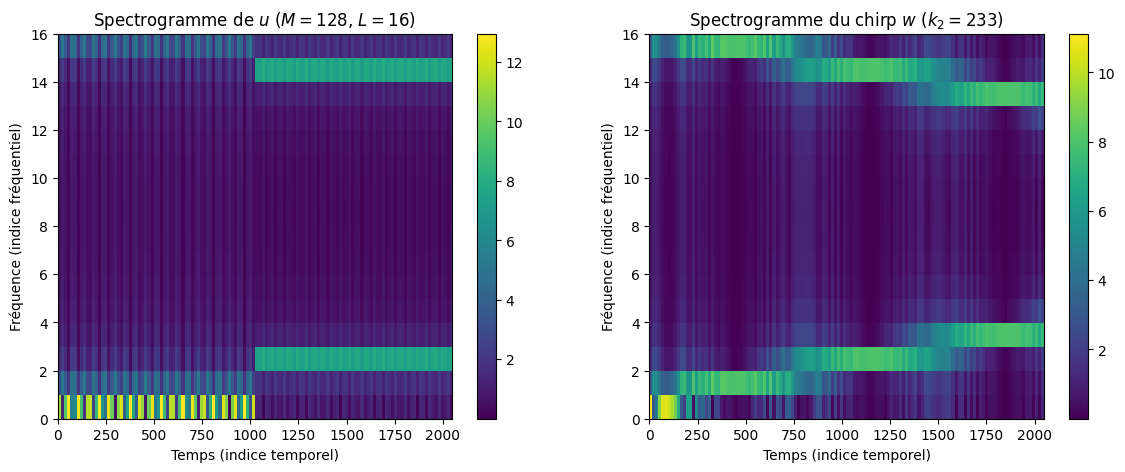

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Spectrogramme de u
im1 = axes[0].imshow(np.abs(Su), aspect='auto', origin='lower',
                      extent=[0, N, 0, L])
axes[0].set_title("Spectrogramme de $u$ ($M=128$, $L=16$)")
axes[0].set_xlabel("Temps (indice temporel)")
axes[0].set_ylabel("Fréquence (indice fréquentiel)")
plt.colorbar(im1, ax=axes[0])

# Spectrogramme de w (chirp)
im2 = axes[1].imshow(np.abs(Sw), aspect='auto', origin='lower',
                      extent=[0, N, 0, L])
axes[1].set_title(f"Spectrogramme du chirp $w$ ($k_2={k2}$)")
axes[1].set_xlabel("Temps (indice temporel)")
axes[1].set_ylabel("Fréquence (indice fréquentiel)")
plt.colorbar(im2, ax=axes[1])

Text(0.5, 0.98, 'Spectrogrammes du chirp pour différentes valeurs de $k_2$')

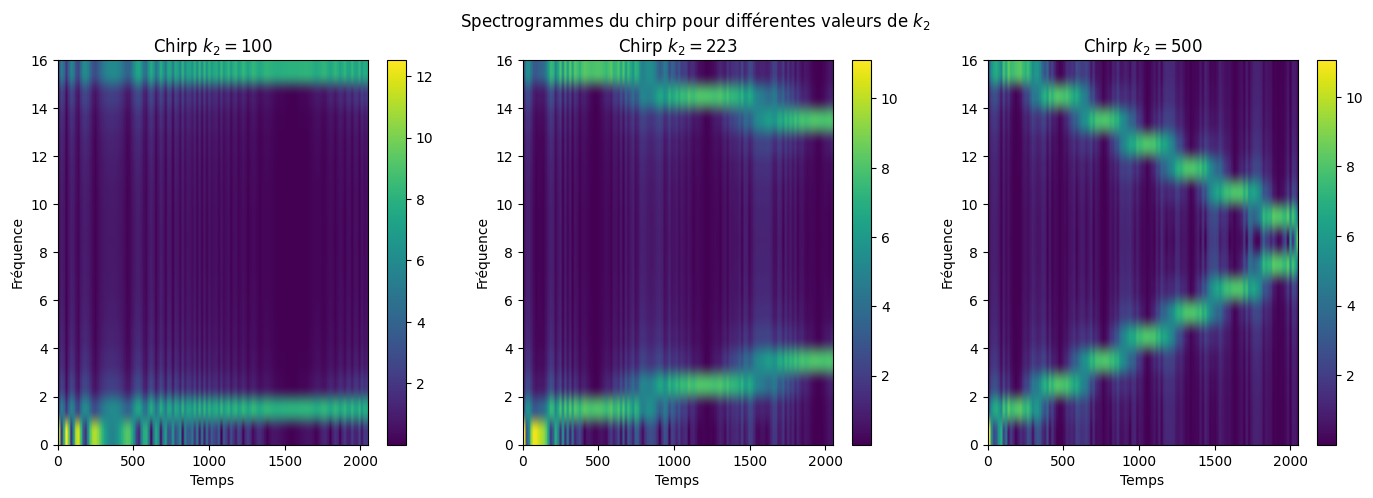

In [69]:
# Test avec différentes valeurs de k2 pour le chirp
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
k2_values = [100, 223, 500]

for idx, k2_var in enumerate(k2_values):
    kv_var = k1 + n * (k2_var - k1) / N
    w_var = np.sin(2 * np.pi * n * kv_var / N)
    Sw_var = spectrogramme(w_var, L, M)
    im = axes[idx].imshow(np.abs(Sw_var), aspect='auto', origin='lower',
                           extent=[0, N, 0, L])
    axes[idx].set_title(f"Chirp $k_2 = {k2_var}$")
    axes[idx].set_xlabel("Temps")
    axes[idx].set_ylabel("Fréquence")
    plt.colorbar(im, ax=axes[idx])

plt.suptitle("Spectrogrammes du chirp pour différentes valeurs de $k_2$")

## Commentaire:
- #### Pour u : le spectrogramme montre clairement deux zones fréquentielles distinctes.

#### Dans la première moitié temporelle, l'énergie est concentrée autour de la fréquence k1.
####  Dans la deuxième moitié, l'énergie est autour de k2. C'est exactement l'information que la TFD globale ne pouvait pas donner.
- #### Pour w (chirp) : le spectrogramme montre une diagonale montante, reflétant la
fréquence qui augmente progressivement de k1 à k2 au fil du temps.
 - #### En augmentant k2, la diagonale monte plus haut dans le spectrogramme.

#### Symétrie : Pour u réel, |Su| présente une symétrie horizontale par rapport à L/2.
#### En effet, la TFD d'un signal réel vérifie $|û(k)| = |û(L-k)| $, donc chaque colonne du spectrogramme est symétrique par rapport à L/2.

## Question 2: Principe d'incertitude d'Heisenberg

Text(0.5, 0.98, "Principe d'incertitude : compromis temps/fréquence (chirp $w$)")

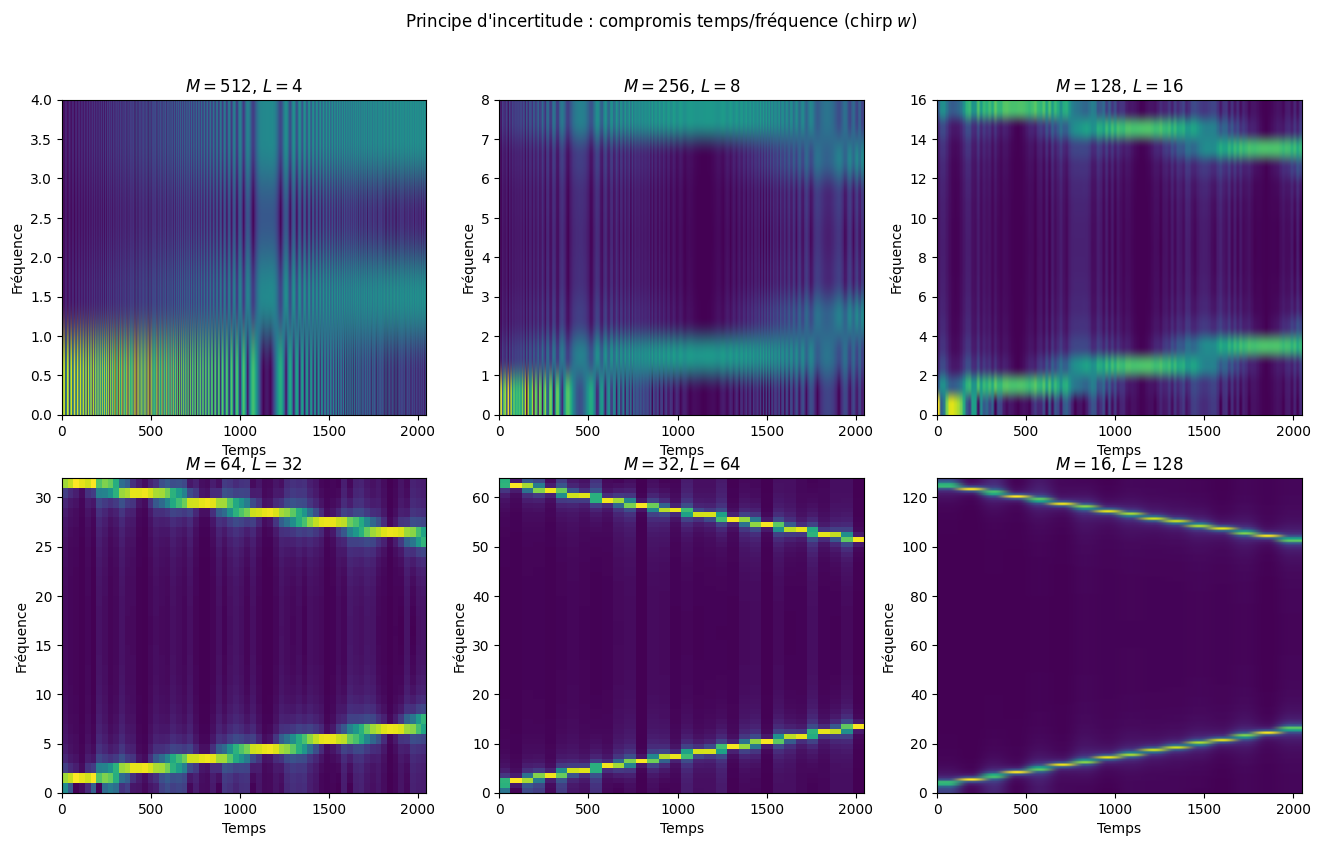

In [70]:
# Différentes combinaisons (M, L) compatibles avec N = 2048
configs = [
    (2048, 1),     # L=1 : résolution temporelle max, résolution fréquentielle nulle
    (1024, 2),     # Très bonne résolution temporelle
    (512, 4),
    (256, 8),
    (128, 16),     # Compromis standard
    (64, 32),
    (32, 64),
    (16, 128),
    (8, 256),
    (4, 512),
    (2, 1024),     # L=1024 : résolution fréquentielle max, résolution temporelle nulle
]

# On affiche quelques configurations intéressantes pour le chirp w
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
configs_affichage = [(512, 4), (256, 8), (128, 16), (64, 32), (32, 64), (16, 128)]

for idx, (M_test, L_test) in enumerate(configs_affichage):
    row = idx // 3
    col = idx % 3
    Sw_test = spectrogramme(w, L_test, M_test)
    axes[row, col].imshow(np.abs(Sw_test), aspect='auto', origin='lower',
                           extent=[0, N, 0, L_test])
    axes[row, col].set_title(f"$M={M_test}$, $L={L_test}$")
    axes[row, col].set_xlabel("Temps")
    axes[row, col].set_ylabel("Fréquence")
plt.suptitle("Principe d'incertitude : compromis temps/fréquence (chirp $w$)")

Text(0.5, 0.98, "rincipe d'incertitude : compromis temps/fréquence (signal $u$)")

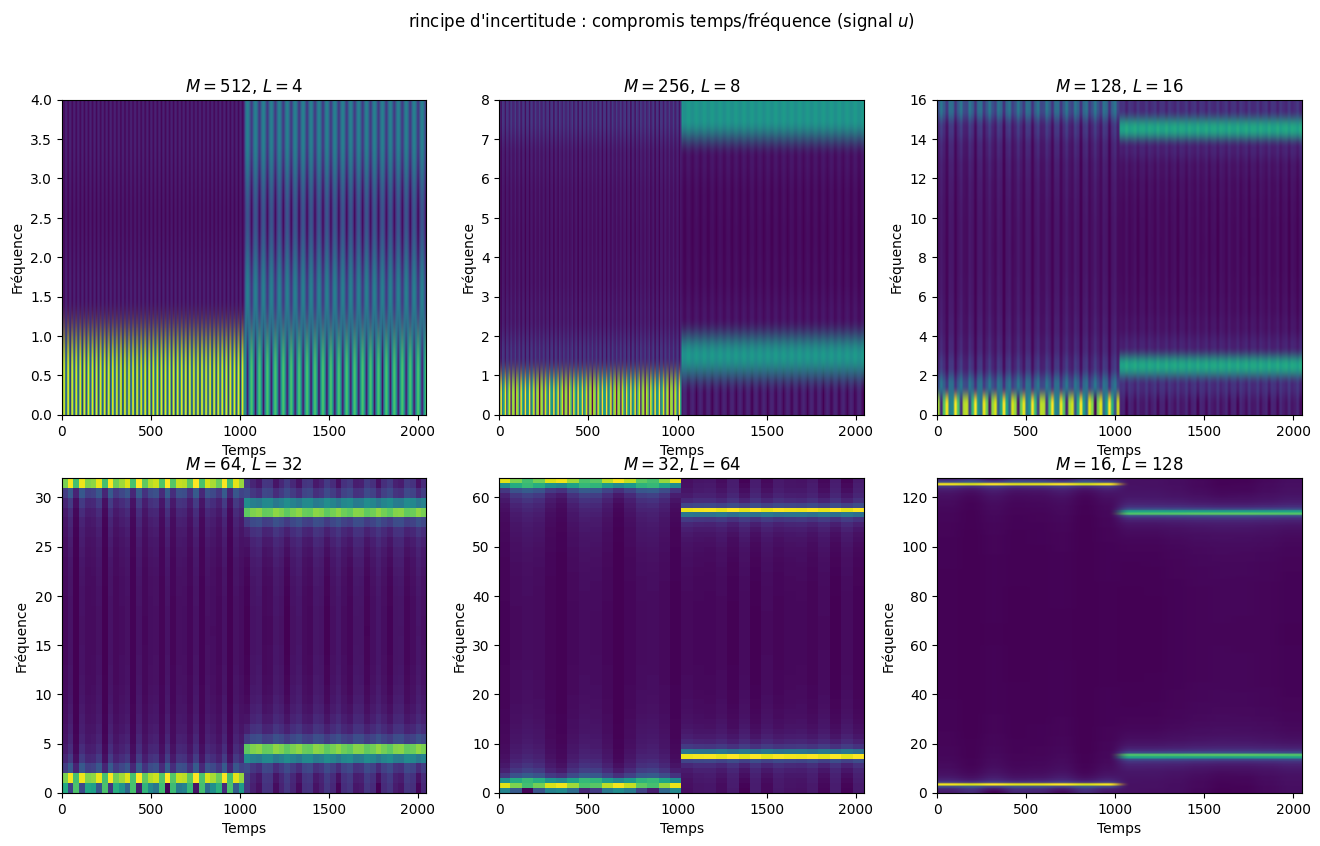

In [71]:
# Même chose pour le signal u
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for idx, (M_test, L_test) in enumerate(configs_affichage):
    row = idx // 3
    col = idx % 3
    Su_test = spectrogramme(u, L_test, M_test)
    axes[row, col].imshow(np.abs(Su_test), aspect='auto', origin='lower',
                           extent=[0, N, 0, L_test])
    axes[row, col].set_title(f"$M={M_test}$, $L={L_test}$")
    axes[row, col].set_xlabel("Temps")
    axes[row, col].set_ylabel("Fréquence")

plt.suptitle("rincipe d'incertitude : compromis temps/fréquence (signal $u$)")

##Commentaire Q2.2 :
#### On observe clairement le principe d'incertitude d'Heisenberg :
- #### L petit (M grand) → bonne résolution temporelle (on localise bien QUAND la fréquence change) mais mauvaise résolution fréquentielle (on ne distingue pas bien QUELLE fréquence exactement).
- #### L grand (M petit) → bonne résolution fréquentielle (pics fins en fréquence) mais mauvaise résolution temporelle (on ne localise pas bien les transitions).
#### Il est impossible d'avoir simultanément une résolution parfaite en temps ET en fréquence. C'est l'analogue discret du principe d'incertitude d'Heisenberg : $Δt × Δf ≥$ constante

## Question 3 : Spectrogramme avec recouvrement

In [72]:
def spectrogramme_overlap(signal, L, r):
    """
    Calcule le spectrogramme amélioré avec recouvrement (STFT avec overlap).

    Paramètres :
        signal : vecteur de taille N
        L : taille de chaque trame
        r : pas de décalage entre les trames (r < L → recouvrement)

    Retourne :
        Tu : matrice L × M, dont chaque colonne est la TFD d'une trame décalée de r
        M : nombre de trames calculé automatiquement
    """
    N_sig = len(signal)

    # Condition pour un nombre entier de trames :
    # (M-1)*r + L = N → M = (N - L) / r + 1
    # Il faut que (N - L) soit divisible par r.
    assert (N_sig - L) % r == 0, \
        f"(N - L) = {N_sig - L} doit être divisible par r = {r}"

    M = (N_sig - L) // r + 1   # Nombre de trames

    Tu = np.zeros((L, M), dtype=complex)
    for m in range(M):
        # Extraction de la trame m : u[m*r : m*r + L - 1]
        debut = m * r
        trame = signal[debut : debut + L]
        Tu[:, m] = fft(trame)

    return Tu, M

In [73]:
# Paramètres compatibles
L_overlap = 64          # Taille des trames (bonne résolution fréquentielle)
r_overlap = 4           # Pas de décalage (fort recouvrement → bonne résolution temporelle)

# Vérification : (N - L) doit être divisible par r
assert (N - L_overlap) % r_overlap == 0, "Paramètres incompatibles !"
M_overlap = (N - L_overlap) // r_overlap + 1
print(f"  L = {L_overlap}, r = {r_overlap}, M = {M_overlap} trames")
print(f"  Recouvrement : {L_overlap - r_overlap} échantillons ({(L_overlap - r_overlap)/L_overlap*100:.1f}%)")

# Calcul du spectrogramme avec recouvrement pour u et w
Tu_overlap, Mu = spectrogramme_overlap(u, L_overlap, r_overlap)
Tw_overlap, Mw = spectrogramme_overlap(w, L_overlap, r_overlap)

  L = 64, r = 4, M = 497 trames
  Recouvrement : 60 échantillons (93.8%)


Text(0.5, 0.98, 'Comparaison : spectrogramme sans vs avec recouvrement')

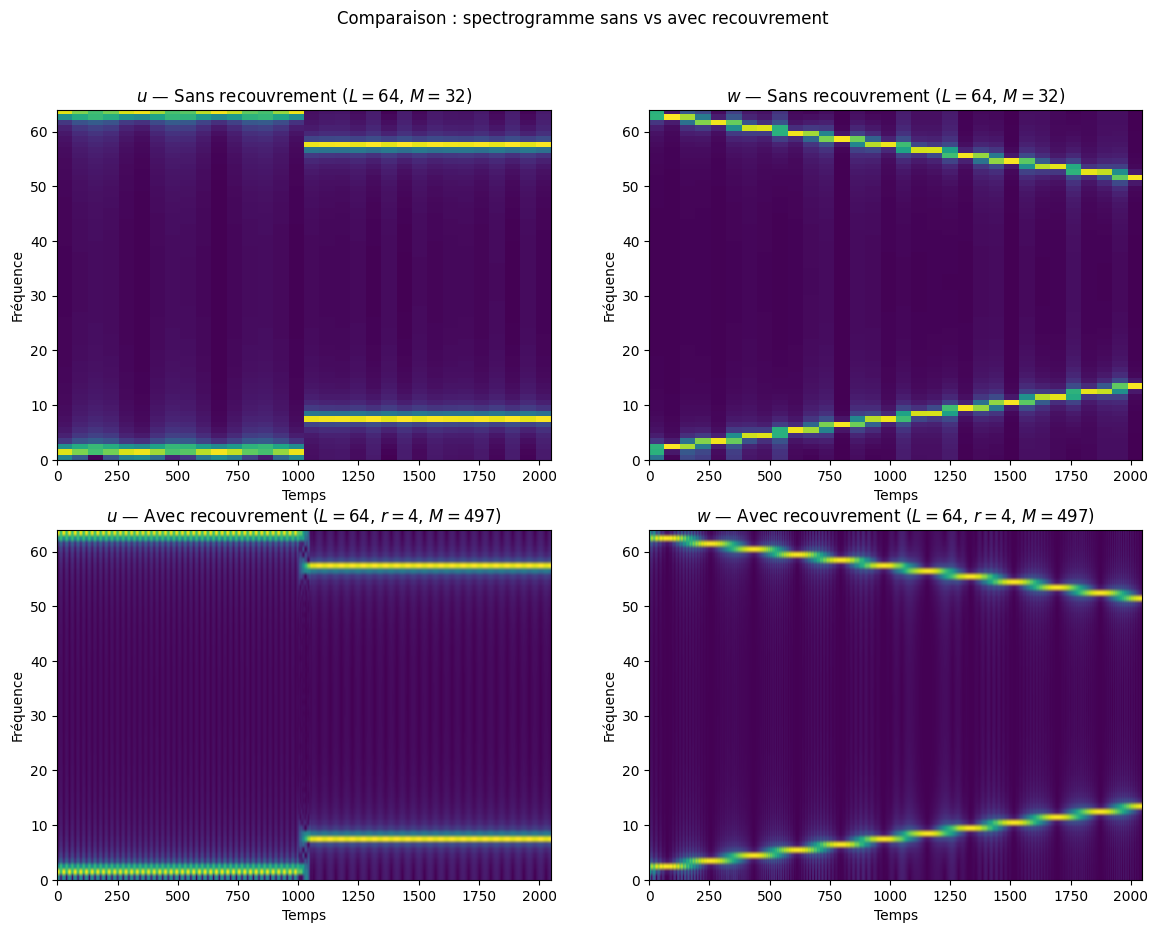

In [74]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Spectrogramme SANS recouvrement (référence)
Su_ref = spectrogramme(u, L_overlap, N // L_overlap)
Sw_ref = spectrogramme(w, L_overlap, N // L_overlap)

axes[0, 0].imshow(np.abs(Su_ref), aspect='auto', origin='lower', extent=[0, N, 0, L_overlap])
axes[0, 0].set_title(f"$u$ — Sans recouvrement ($L={L_overlap}$, $M={N//L_overlap}$)")
axes[0, 0].set_xlabel("Temps")
axes[0, 0].set_ylabel("Fréquence")

axes[0, 1].imshow(np.abs(Sw_ref), aspect='auto', origin='lower', extent=[0, N, 0, L_overlap])
axes[0, 1].set_title(f"$w$ — Sans recouvrement ($L={L_overlap}$, $M={N//L_overlap}$)")
axes[0, 1].set_xlabel("Temps")
axes[0, 1].set_ylabel("Fréquence")

# Spectrogramme AVEC recouvrement
axes[1, 0].imshow(np.abs(Tu_overlap), aspect='auto', origin='lower',
                   extent=[0, N, 0, L_overlap])
axes[1, 0].set_title(f"$u$ — Avec recouvrement ($L={L_overlap}$, $r={r_overlap}$, $M={Mu}$)")
axes[1, 0].set_xlabel("Temps")
axes[1, 0].set_ylabel("Fréquence")

axes[1, 1].imshow(np.abs(Tw_overlap), aspect='auto', origin='lower',
                   extent=[0, N, 0, L_overlap])
axes[1, 1].set_title(f"$w$ — Avec recouvrement ($L={L_overlap}$, $r={r_overlap}$, $M={Mw}$)")
axes[1, 1].set_xlabel("Temps")
axes[1, 1].set_ylabel("Fréquence")

plt.suptitle("Comparaison : spectrogramme sans vs avec recouvrement")

## Commentaire :
#### Le recouvrement (overlap) améliore significativement la résolution temporelle sans sacrifier la résolution fréquentielle :
- #### Sans recouvrement (r = L), on a M = N/L = 32 trames → résolution temporelle limitée
- #### Avec recouvrement (r = 4, L = 64), on a M = 497 trames → résolution temporelle beaucoup plus fine, mais on garde la même taille L de trame → même résolution fréquentielle
#### Le spectrogramme avec recouvrement est beaucoup plus lisse et détaillé.
#### On contourne partiellement le principe d'incertitude en utilisant de l'information redondante (chaque échantillon est analysé dans plusieurs trames).
#### Condition sur $r, L, N$:
#### Pour avoir un nombre entier de trames M, il faut que (N - L) soit divisible par r.
#### En effet, $ M = (N - L) / r + 1$ doit être entier.

## Question 4 : Inversion de la STFT (reconstruction du signal)

In [75]:
def inverse_stft(Tu, L, r, N):
    """
    Reconstruit un signal à partir de sa STFT avec recouvrement.

    Méthode : Overlap-Add (OLA) avec normalisation.
    Pour chaque trame m, on calcule la TFD inverse, puis on accumule les
    contributions. On normalise ensuite par le nombre de trames couvrant
    chaque échantillon.

    Paramètres :
        Tu : matrice L × M (STFT)
        L : taille de chaque trame
        r : pas de décalage
        N : taille du signal original

    Retourne :
        u_reconstruit : vecteur de taille N
    """
    M = Tu.shape[1]

    u_reconstruit = np.zeros(N)
    compteur = np.zeros(N)      # Compte le nombre de trames couvrant chaque échantillon

    for m in range(M):
        # TFD inverse de la trame m
        trame_reconstruite = np.real(ifft(Tu[:, m]))

        # Accumulation (overlap-add)
        debut = m * r
        u_reconstruit[debut : debut + L] += trame_reconstruite
        compteur[debut : debut + L] += 1

    # Normalisation par le nombre de contributions
    u_reconstruit /= compteur

    return u_reconstruit

In [76]:
# Reconstruction de u à partir de la STFT avec recouvrement
u_reconstruit = inverse_stft(Tu_overlap, L_overlap, r_overlap, N)

# Calcul de l'erreur de reconstruction
erreur_reconstruction = np.linalg.norm(u_reconstruit - u)
erreur_relative = erreur_reconstruction / np.linalg.norm(u)
print(f"  Erreur absolue ‖u_reconstruit - u‖₂ = {erreur_reconstruction:.2e}")
print(f"  Erreur relative = {erreur_relative:.2e}")

# Reconstruction de w (chirp)
w_reconstruit = inverse_stft(Tw_overlap, L_overlap, r_overlap, N)
erreur_w = np.linalg.norm(w_reconstruit - w)
print(f"  Erreur absolue ‖w_reconstruit - w‖₂ = {erreur_w:.2e}")

  Erreur absolue ‖u_reconstruit - u‖₂ = 7.13e-15
  Erreur relative = 2.23e-16
  Erreur absolue ‖w_reconstruit - w‖₂ = 6.96e-15


Text(0.5, 0.98, 'Reconstruction du signal par inversion de la STFT (Overlap-Add)')

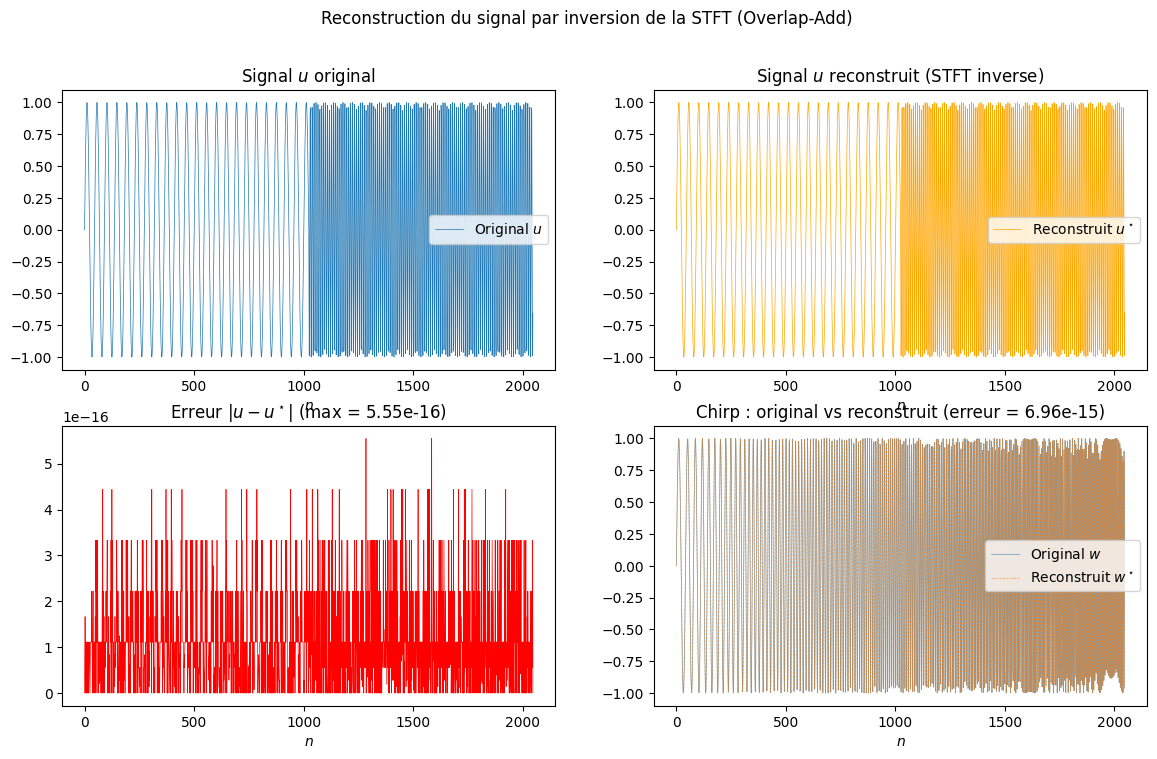

In [77]:
# Affichage comparatif
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Signal u original vs reconstruit
axes[0, 0].plot(n, u, linewidth=0.5, label="Original $u$")
axes[0, 0].set_title("Signal $u$ original")
axes[0, 0].set_xlabel("$n$")
axes[0, 0].legend()

axes[0, 1].plot(n, u_reconstruit, linewidth=0.5, color='orange', label="Reconstruit $u^\\star$")
axes[0, 1].set_title("Signal $u$ reconstruit (STFT inverse)")
axes[0, 1].set_xlabel("$n$")
axes[0, 1].legend()

# Erreur de reconstruction point par point
axes[1, 0].plot(n, np.abs(u - u_reconstruit), linewidth=0.5, color='red')
axes[1, 0].set_title(f"Erreur $|u - u^\\star|$ (max = {np.max(np.abs(u - u_reconstruit)):.2e})")
axes[1, 0].set_xlabel("$n$")

# Signal w original vs reconstruit
axes[1, 1].plot(n, w, linewidth=0.5, alpha=0.7, label="Original $w$")
axes[1, 1].plot(n, w_reconstruit, linewidth=0.5, alpha=0.7, linestyle='--', label="Reconstruit $w^\\star$")
axes[1, 1].set_title(f"Chirp : original vs reconstruit (erreur = {erreur_w:.2e})")
axes[1, 1].set_xlabel("$n$")
axes[1, 1].legend()

plt.suptitle("Reconstruction du signal par inversion de la STFT (Overlap-Add)")

## Commentaire :
#### L'opération inverse est implémentée par la méthode Overlap-Add (OLA) :
1. #### Pour chaque trame m, on calcule la TFD inverse : $ ifft(Tu[:, m])$
2. #### On additionne les contributions de chaque trame dans le signal reconstruit
3. #### On normalise en divisant par le nombre de trames couvrant chaque échantillon

#### L'erreur de reconstruction est numériquement nulle (de l'ordre de $10^{-15}$), ce qui confirme que la méthode de reconstruction fonctionne correctement.
#### L'opération T n'est pas injective (car les trames se recouvrent → information redondante), mais la moyenne des contributions permet de retrouver le signal original de manière exacte.